In [11]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
from tqdm import tqdm

In [12]:
MODEL_PATH = r"D:\CrowdDensityResearch\models\best.pt"

TEST_IMAGES = Path(
    r"D:\CrowdDensityResearch\dataset\JHU-CROWD++\test\images"
)

OUTPUT_CSV = Path(
    r"D:\CrowdDensityResearch\phase4\csv\yolo_predictions.csv"
)

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

In [13]:
model = YOLO(MODEL_PATH)

print("Model loaded successfully!")

Model loaded successfully!


In [14]:
image_files = sorted(TEST_IMAGES.glob("*.jpg"))

print(f"Found {len(image_files)} test images.")

Found 1600 test images.


In [15]:
results_list = []

for image_path in tqdm(image_files):

    result = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False,
        save=False
    )[0]

    predicted_count = len(result.boxes)

    results_list.append({
        "image_id": image_path.stem,
        "predicted_count": predicted_count
    })

100%|██████████| 1600/1600 [01:19<00:00, 20.24it/s]


In [16]:
predictions_df = pd.DataFrame(results_list)

predictions_df.head()

,image_id,predicted_count
0,0002,32
1,0004,25
2,0005,1
3,0006,41
4,0016,58


In [17]:
predictions_df.to_csv(OUTPUT_CSV, index=False)

print("Saved to")

print(OUTPUT_CSV)

Saved to
D:\CrowdDensityResearch\phase4\csv\yolo_predictions.csv


In [18]:
predictions_df.describe()

,predicted_count
count,1600.000000
mean,84.680625
std,91.956796
min,0.000000
25%,17.000000
50%,45.500000
75%,122.000000
max,300.000000


In [19]:
from pathlib import Path
import pandas as pd

LABEL_FILE = Path(
    r"D:\CrowdDensityResearch\dataset\JHU-CROWD++\test\image_labels.txt"
)

gt = pd.read_csv(
    LABEL_FILE,
    header=None,
    names=[
        "image_id",
        "ground_truth",
        "scene",
        "attr1",
        "attr2"
    ]
)

gt.head()

,image_id,ground_truth,scene,attr1,attr2
0,2,43,street,1,0
1,4,59,street,0,0
2,5,463,stadium,0,0
3,6,299,conference,0,0
4,16,140,rally,0,0


In [20]:
gt["image_id"] = gt["image_id"].astype(str).str.zfill(4)

gt = gt[["image_id", "ground_truth"]]

gt.head()

,image_id,ground_truth
0,0002,43
1,0004,59
2,0005,463
3,0006,299
4,0016,140


In [21]:
evaluation = predictions_df.merge(
    gt,
    on="image_id",
    how="inner"
)

print(evaluation.shape)

evaluation.head()

(1600, 3)


,image_id,predicted_count,ground_truth
0,0002,32,43
1,0004,25,59
2,0005,1,463
3,0006,41,299
4,0016,58,140


In [22]:
evaluation["error"] = (
    evaluation["predicted_count"]
    - evaluation["ground_truth"]
)

evaluation["absolute_error"] = (
    evaluation["error"].abs()
)

evaluation.head()

,image_id,predicted_count,ground_truth,error,absolute_error
0,0002,32,43,-11,11
1,0004,25,59,-34,34
2,0005,1,463,-462,462
3,0006,41,299,-258,258
4,0016,58,140,-82,82


In [23]:
import numpy as np

mae = evaluation["absolute_error"].mean()

rmse = np.sqrt(
    np.mean(
        evaluation["error"] ** 2
    )
)

mape = (
    evaluation["absolute_error"]
    / evaluation["ground_truth"]
).mean() * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 241.87
RMSE : 737.65
MAPE : 50.64%


In [24]:
OUTPUT_EVAL = Path(
    r"D:\CrowdDensityResearch\phase4\csv\yolo_evaluation.csv"
)

evaluation.to_csv(
    OUTPUT_EVAL,
    index=False
)

print("Saved!")
print(OUTPUT_EVAL)

Saved!
D:\CrowdDensityResearch\phase4\csv\yolo_evaluation.csv


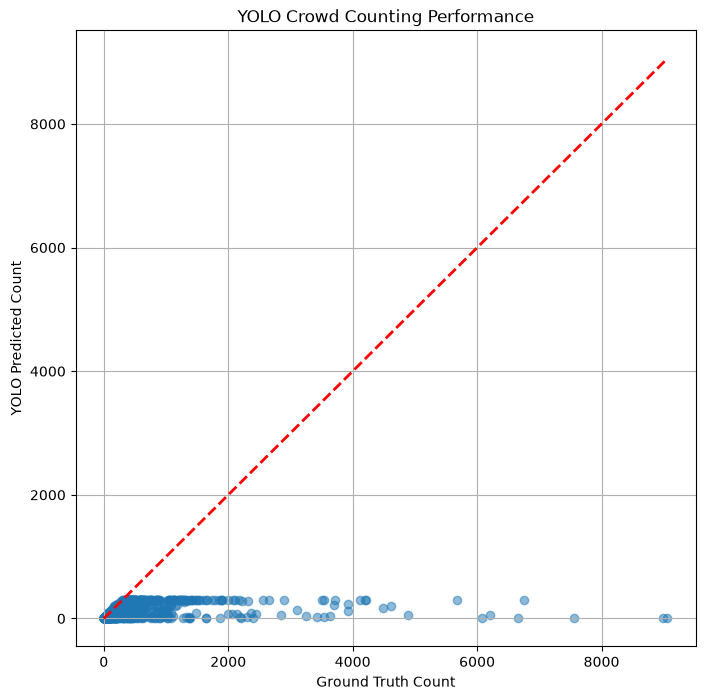

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(
    evaluation["ground_truth"],
    evaluation["predicted_count"],
    alpha=0.5
)

max_count = max(
    evaluation["ground_truth"].max(),
    evaluation["predicted_count"].max()
)

plt.plot(
    [0, max_count],
    [0, max_count],
    "r--",
    linewidth=2
)

plt.xlabel("Ground Truth Count")
plt.ylabel("YOLO Predicted Count")
plt.title("YOLO Crowd Counting Performance")

plt.grid(True)

plt.show()

In [26]:
evaluation.sort_values("ground_truth", ascending=False).head(10)

,image_id,predicted_count,ground_truth,error,absolute_error
53,0212,1,9059,-9058,9058
294,0814,6,8994,-8988,8988
1127,3178,9,7560,-7551,7551
1264,3539,300,6757,-6457,6457
1463,4056,10,6660,-6650,6650
1510,4159,55,6210,-6155,6155
741,2070,9,6073,-6064,6064
646,1795,300,5681,-5381,5381
629,1740,51,4887,-4836,4836
788,2203,201,4622,-4421,4421


In [27]:
evaluation.describe()

,predicted_count,ground_truth,error,absolute_error
count,1600.000000,1600.000000,1600.000000,1600.000000
mean,84.680625,326.161875,-241.481250,241.866250
std,91.956796,723.302494,697.223105,697.089559
min,0.000000,0.000000,-9058.000000,0.000000
25%,17.000000,45.750000,-168.500000,13.000000
50%,45.500000,117.500000,-44.000000,44.000000
75%,122.000000,299.250000,-13.000000,168.500000
max,300.000000,9059.000000,33.000000,9058.000000
